# Practice 11 — Object Detection

**Goal:** run a pretrained detector, read what it returns — *where*, not only *what* — and score it with mAP.

| Task | Output per object | Numbers per object |
|:---|:---|:---|
| Classification | one label for the whole image | 1 class index |
| Object detection | one axis-aligned box | 4 coordinates + class + confidence |
| Instance segmentation | one per-pixel mask | a 0/1 grid + class + confidence |

- Nothing is trained here → the weights arrive pretrained on the 80 COCO classes

---
## Step 0. Setup

- `ultralytics` → the YOLO models with their `predict` and `val` methods
- A path given to `YOLO(...)` → the weights are downloaded there, not into the working directory

In [1]:
import subprocess
import sys

try:
    import ultralytics
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'], check=True)
    import ultralytics

print(f'ultralytics {ultralytics.__version__}')

ultralytics 8.4.194


In [2]:
import urllib.request
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO

np.random.seed(42)
torch.manual_seed(42)

# the weights and the images are saved under these two folders; val() writes its runs to runs/
BUILD = Path('build')
DATA = Path('data')
BUILD.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

print(f'GPU available : {torch.cuda.is_available()}')

GPU available : True


image shape : (1380, 2070, 3)   height, width, channels


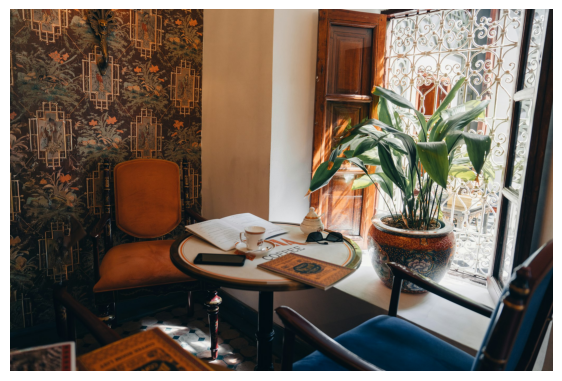

In [3]:
url_room = 'https://images.unsplash.com/photo-1760681557777-bfac1f18cf90?ixlib=rb-4.1.0&auto=format&fit=crop&q=80&w=2070'
image_path_room = DATA / 'room.jpg'
if not image_path_room.exists():
    urllib.request.urlretrieve(url_room, image_path_room)

url_bus = 'https://ultralytics.com/images/bus.jpg'
image_path_bus = DATA / 'bus.jpg'
if not image_path_bus.exists():
    urllib.request.urlretrieve(url_bus, image_path_bus)

image_room = np.array(Image.open(image_path_room).convert('RGB'))
print(f'image shape : {image_room.shape}   height, width, channels')

plt.figure(figsize=(7, 5))
plt.imshow(image_room)
plt.axis('off')
plt.show()

---
## Step 1. Running the Detector

- `yolo11n` → the smallest YOLO11, already knows the 80 COCO classes
- `conf=0.25` → drops detections below 25% confidence
- `predict` returns a list, one `Results` per input image; `result.plot(pil=True)` draws its boxes as an RGB image for matplotlib

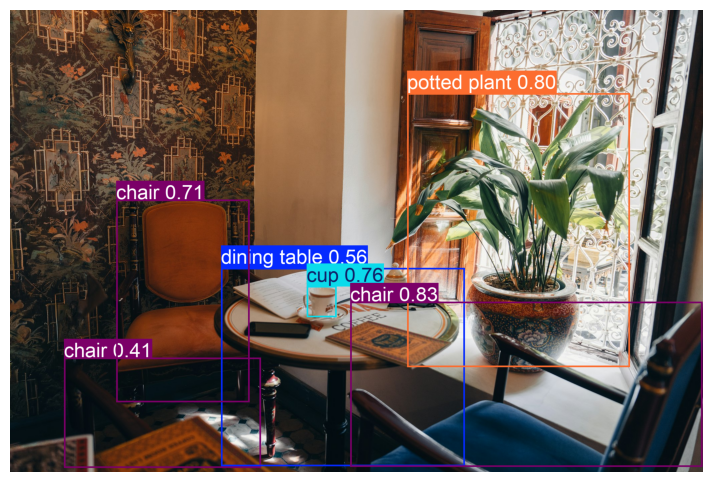

In [4]:
detection_model = YOLO(str(BUILD / 'yolo11n.pt'))
detection_results = detection_model.predict(source=str(image_path_room), conf=0.25, verbose=False)
detection_result = detection_results[0]  # we have only one result from one image

plt.figure(figsize=(9, 6))
plt.imshow(detection_result.plot(pil=True))  # pil=True -> an RGB image; plot() alone gives a BGR numpy array
plt.axis('off')
plt.show()

---
## Step 2. What Is Inside `result.boxes`

- `boxes[idx]` prints every attribute of one object; change `idx` to look at another

| Attribute | Shape | Meaning |
|:---|:---|:---|
| `xyxy` | (N, 4) | corners in pixels, `(x1, y1, x2, y2)` |
| `xywh` · `xyxyn` · `xywhn` | (N, 4) | centre–size form; `n` = divided by the image size |
| `conf` | (N,) | confidence |
| `cls` | (N,) | class index, a float → `int()` for `names` |
| `data` | (N, 6) | all of the above in one tensor |

In [5]:
idx = 0
print(detection_result.boxes[idx])

ultralytics.engine.results.Boxes object with attributes:

cls: tensor([56.], device='cuda:0')
conf: tensor([0.8330], device='cuda:0')
data: tensor([[1.0166e+03, 8.7137e+02, 2.0690e+03, 1.3650e+03, 8.3303e-01, 5.6000e+01]], device='cuda:0')
id: None
is_track: False
orig_shape: (1380, 2070)
shape: torch.Size([1, 6])
xywh: tensor([[1542.7952, 1118.1709, 1052.3307,  493.6074]], device='cuda:0')
xywhn: tensor([[0.7453, 0.8103, 0.5084, 0.3577]], device='cuda:0')
xyxy: tensor([[1016.6298,  871.3672, 2068.9604, 1364.9746]], device='cuda:0')
xyxyn: tensor([[0.4911, 0.6314, 0.9995, 0.9891]], device='cuda:0')


- `result.names` → the 80 class names by index; one line per object with its confidence

In [6]:
for index in range(len(detection_result.boxes)):
    class_name = detection_result.names[int(detection_result.boxes.cls[index])]
    confidence = float(detection_result.boxes.conf[index])
    print(f'{class_name:<14s} {confidence:.3f}')

chair          0.833
potted plant   0.801
cup            0.760
chair          0.710
dining table   0.564
chair          0.412


---
## What `source` Accepts

| `source` | Form |
|:---|:---|
| path | `str`: an image file, a folder or a video |
| URL | `str` ending in an image extension (`.jpg`, …) → downloaded next to the notebook |
| `PIL.Image` | as loaded |
| `numpy` array | `(H, W, 3)` `uint8` in **BGR** order (OpenCV convention) |
| `torch` tensor | `(B, 3, H, W)` float in [0, 1], RGB |

- A link without an extension (the Unsplash one) works only in recent library versions; older ones take it for a video stream and hang → download it yourself, as Step 0 did

In [7]:
print(np.shape(image_room))

(1380, 2070, 3)


In [8]:
# Method 1: path
# source = str(image_path_room)

# Method 2: URL, ends in .jpg (url_room has no extension and hangs in older library versions)
# source = url_room

# Method 3: PIL image
# source = Image.fromarray(image_room)

# Method 4: numpy array, BGR copy of the RGB array
source = image_room[:, :, ::-1].copy() # ::-1 read RGB as BGR

print(np.shape(source))
result_from_source = detection_model.predict(source=source, conf=0.25, verbose=False)[0]
print(result_from_source.boxes[0])

(1380, 2070, 3)
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([56.], device='cuda:0')
conf: tensor([0.8330], device='cuda:0')
data: tensor([[1.0166e+03, 8.7137e+02, 2.0690e+03, 1.3650e+03, 8.3303e-01, 5.6000e+01]], device='cuda:0')
id: None
is_track: False
orig_shape: (1380, 2070)
shape: torch.Size([1, 6])
xywh: tensor([[1542.7952, 1118.1709, 1052.3307,  493.6074]], device='cuda:0')
xywhn: tensor([[0.7453, 0.8103, 0.5084, 0.3577]], device='cuda:0')
xyxy: tensor([[1016.6298,  871.3672, 2068.9604, 1364.9746]], device='cuda:0')
xyxyn: tensor([[0.4911, 0.6314, 0.9995, 0.9891]], device='cuda:0')


---
## Step 3. Drawing from the Coordinates

- Row `idx` of `boxes.xyxy` → one matplotlib rectangle; `plot()` does this for every row

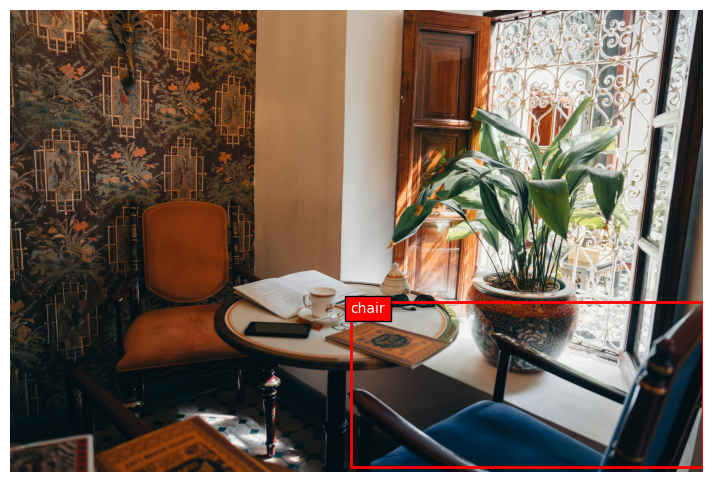

In [9]:
idx = 0
x1, y1, x2, y2 = detection_result.boxes.xyxy[idx].cpu().numpy()
class_name = detection_result.names[int(detection_result.boxes.cls[idx])]

plt.figure(figsize=(9, 6))
plt.imshow(image_room)
plt.gca().add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='red', linewidth=2))
plt.text(x1, y1, class_name, color='white', va='top', bbox=dict(facecolor='red'))
plt.axis('off')
plt.show()

- `(x1, y1)` is the top-left corner and `(x2, y2)` the bottom-right → width `x2 - x1`, height `y2 - y1`

---
## Step 4. The Confidence Threshold

- Only `conf` changes between the two calls → the boxes that survive, their confidences in the labels

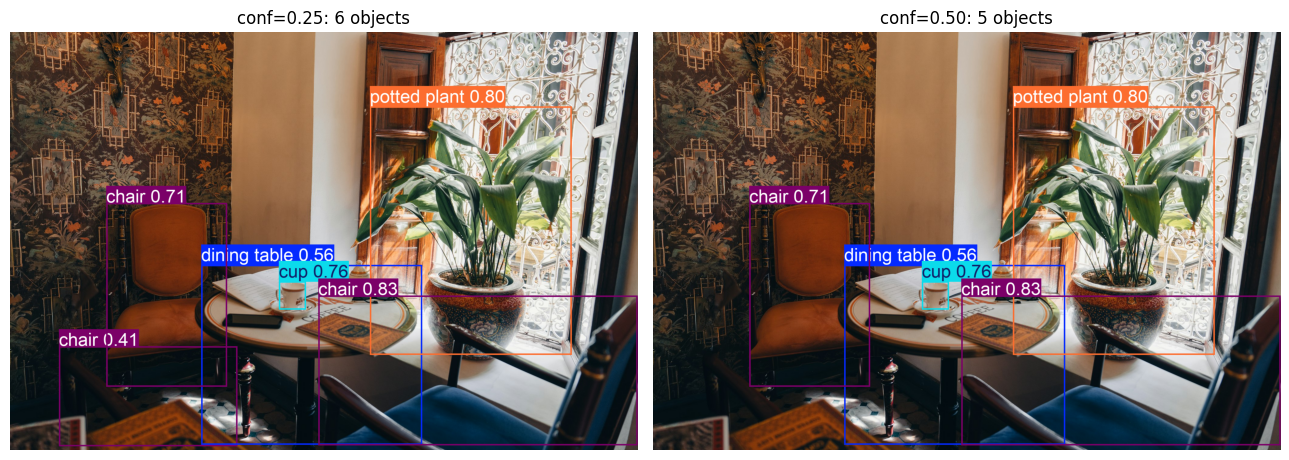

In [10]:
result_25 = detection_model.predict(source=str(image_path_room), conf=0.25, verbose=False)[0]
result_50 = detection_model.predict(source=str(image_path_room), conf=0.50, verbose=False)[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(result_25.plot(pil=True))
axes[0].set_title(f'conf=0.25: {len(result_25.boxes)} objects')

axes[1].imshow(result_50.plot(pil=True))
axes[1].set_title(f'conf=0.50: {len(result_50.boxes)} objects')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- `chair` 0.41 is the only detection below 0.50 → it is gone on the right, the other five stay

---
## Step 5. NMS

- The detector proposes many boxes → several pass `conf` on the same object
- NMS (non-maximum suppression) keeps the most confident box of a class and removes the others overlapping it by IoU above `iou`, a `predict` argument with default 0.7
- `iou=1.0` → nothing is removed: the raw list behind Step 1

iou=1.0 (NMS off) : 52 boxes
iou=0.7 (default) :  6 boxes


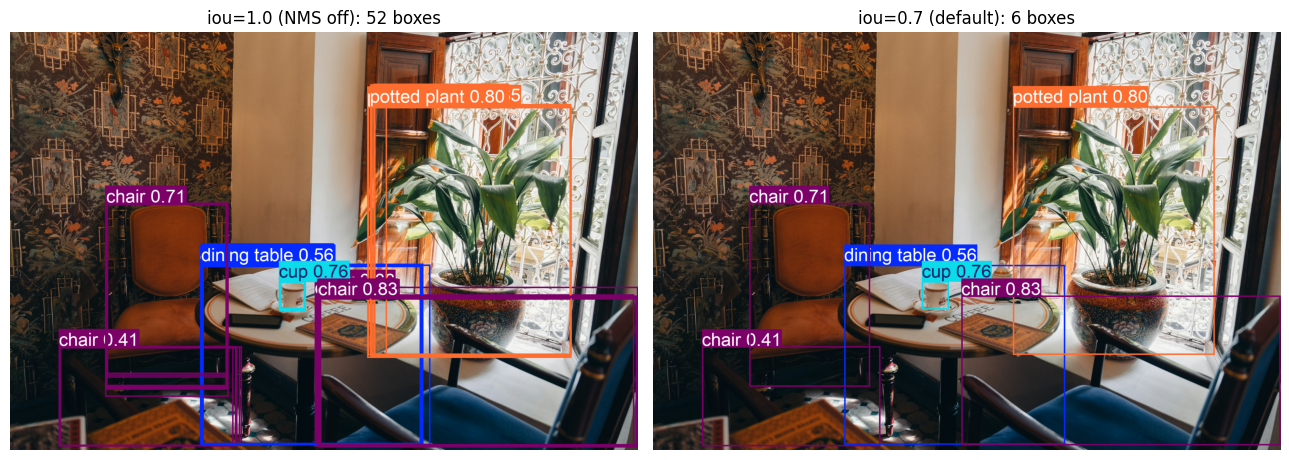

In [11]:
raw_result = detection_model.predict(source=str(image_path_room), conf=0.25, iou=1.0, verbose=False)[0]

print(f'iou=1.0 (NMS off) : {len(raw_result.boxes):2d} boxes')
print(f'iou=0.7 (default) : {len(detection_result.boxes):2d} boxes')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(raw_result.plot(pil=True))
axes[0].set_title(f'iou=1.0 (NMS off): {len(raw_result.boxes)} boxes')

axes[1].imshow(detection_result.plot(pil=True))
axes[1].set_title(f'iou=0.7 (default): {len(detection_result.boxes)} boxes')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- Left: 52 boxes pass `conf=0.25`, many of them on the same chair, cup, plant or table
- Right: NMS keeps one box per object → the 6 of Step 1

---
## Step 6. Scoring the Detector: mAP

- Scoring needs labelled boxes → `coco8`, 8 COCO images with labels, 4 for validation
- A YOLO dataset = `images/` and `labels/` with matching file names; one `.txt` per image, one line per object: `class cx cy w h`, centre and size over the image size
- The same three cells score any dataset in this layout, yours included

coco8/images/train  4 files
coco8/images/val    4 files
coco8/labels/train  4 files
coco8/labels/val    4 files

000000000061.txt
0 0.445688 0.480615 0.075125 0.117295
0 0.640086 0.471742 0.0508281 0.0814344
20 0.643211 0.558852 0.129828 0.097623
20 0.459703 0.592121 0.22175 0.159242
0 0.435383 0.45832 0.0534531 0.111025


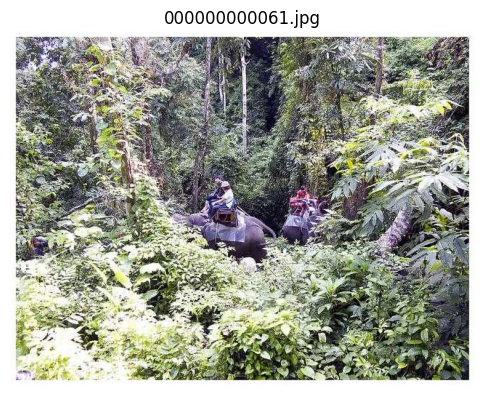

In [12]:
import zipfile

coco8_dir = DATA / 'coco8'
if not coco8_dir.exists():
    urllib.request.urlretrieve(
        'https://github.com/ultralytics/assets/releases/download/v0.0.0/coco8.zip', BUILD / 'coco8.zip')
    with zipfile.ZipFile(BUILD / 'coco8.zip') as archive:
        archive.extractall(DATA)

for folder in ['images/train', 'images/val', 'labels/train', 'labels/val']:
    n_files = len(list((coco8_dir / folder).glob('*')))
    print(f'coco8/{folder:<13s} {n_files} files')

label_path = coco8_dir / 'labels' / 'val' / '000000000061.txt'
print()
print(label_path.name)
print(label_path.read_text().strip())

plt.figure(figsize=(6, 6))
plt.imshow(Image.open(coco8_dir / 'images' / 'val' / '000000000061.jpg'))
plt.title('000000000061.jpg')
plt.axis('off')
plt.show()

- Five lines → five objects: three of class 0 = `person`, two of class 20 = `elephant` in COCO's numbering

- The library reads a dataset through a yaml file → where the `train` and `val` images are (labels are found by swapping `images` for `labels`) and what each class index means
- `names` → the 80 COCO classes in the model's order here; your own dataset lists its own

In [13]:
coco8_yaml_path = (DATA / 'coco8.yaml').resolve()

# the two folders are written relative to the folder this file sits in
with open(coco8_yaml_path, 'w', encoding='utf-8') as yaml_file:
    yaml_file.write('train: coco8/images/train\n')
    yaml_file.write('val: coco8/images/val\n')
    yaml_file.write('names:\n')
    for class_index, class_name in detection_model.names.items():
        yaml_file.write(f'  {class_index}: {class_name}\n')

# 83 lines: two folders, names:, then the 80 names
yaml_lines = coco8_yaml_path.read_text().splitlines()
for line in yaml_lines[:5]:
    print(line)
print('  ...')
print(yaml_lines[-1])

train: coco8/images/train
val: coco8/images/val
names:
  0: person
  1: bicycle
  ...
  79: toothbrush


- `val()` scores the detector on one split → precision, recall and mAP per class; it keeps boxes down to `conf=0.001`, so it sees more than `predict` at 0.25
- mAP@50 → a match needs IoU ≥ 0.5; mAP@50-95 → averaged over IoU 0.5 to 0.95, rewarding tight boxes
- `split='val'` is the default, `'train'` or `'test'` score those folders of the yaml; `name` → the run folder `runs/detect/coco8` with the pictures

In [14]:
coco_metrics = detection_model.val(data=str(coco8_yaml_path), split='val', name='coco8')  # or split='train' / 'test'

print()
print(f'mAP@50    : {coco_metrics.box.map50:.3f}')
print(f'mAP@50-95 : {coco_metrics.box.map:.3f}')

Ultralytics 8.4.194  Python-3.11.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA TITAN RTX, 24576MiB)


YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 319.6±193.9 MB/s, size: 54.0 KB)


val: Scanning D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\data\coco8\labels\val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 14.9it/s 0.1s

                   all          4         17       0.57       0.85      0.854      0.631


... (5 outputs left out)

          potted plant          1          1      0.847          1      0.995      0.895


Speed: 0.6ms preprocess, 7.4ms inference, 0.0ms loss, 0.7ms postprocess per image


Results saved to D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\runs\detect\coco8-3



mAP@50    : 0.854
mAP@50-95 : 0.631


- One row per class that has labels, plus `all`: 4 images, 17 labelled objects, mAP@50 0.854
- mAP@50-95 0.631 → the same predictions scored again at IoU 0.55, 0.60, …, 0.95 and averaged; stricter matching, lower score
- 4 images → a demonstration; the real COCO validation set has 5,000

- The run folder holds pictures of the labels `val()` read and of its predictions, and the precision–recall curve whose area per class is the AP

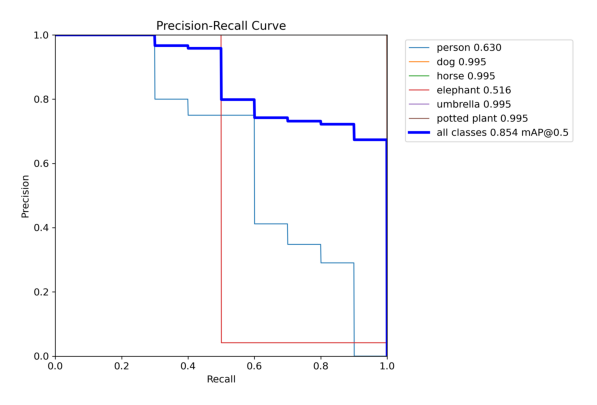

In [15]:
val_dir = Path(coco_metrics.save_dir)

plt.figure(figsize=(8, 5))
plt.imshow(Image.open(val_dir / 'BoxPR_curve.png'))
plt.axis('off')
plt.show()

- A model that is not a YOLO → the same mAP comes from `torchmetrics` (`MeanAveragePrecision`) or COCO's official `pycocotools`; both take the predicted boxes with their scores and classes, and the label boxes

---
## Step 7. The Same Call on Another Image

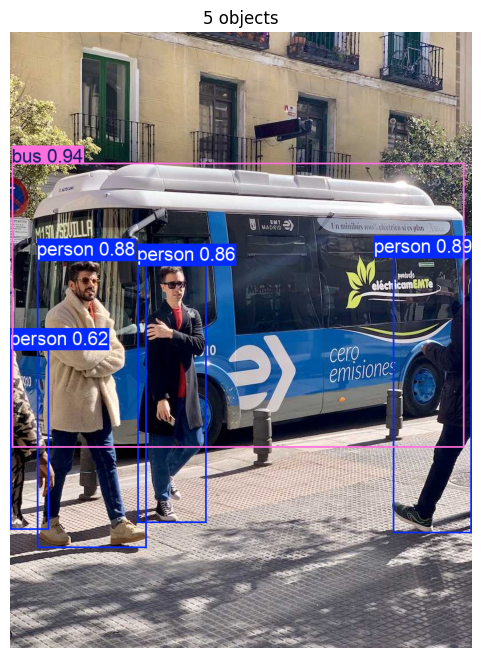

In [16]:
result_bus = detection_model.predict(source=str(image_path_bus), conf=0.25, verbose=False)[0]

plt.figure(figsize=(7, 8))
plt.imshow(result_bus.plot(pil=True))
plt.title(f'{len(result_bus.boxes)} objects')
plt.axis('off')
plt.show()

- 5 objects: the bus and four people; the one cut by the left edge gets the lowest confidence

---
## Summary

| Result | Holds | Note |
|:---|:---|:---|
| Detection | `boxes`: `xyxy` · `conf` · `cls`, one row per object | `conf` drops weak detections, `plot()` draws them |
| NMS | `iou` threshold, default 0.7 | duplicates collapse to the most confident box |
| mAP | `val(data=yaml, split=..., name=...)` → `images/` + `labels/` | @50 loose match, @50-95 tight boxes too |

---
## Exercises

1. `conf=0.7`, rerun Step 4 — which objects disappear, and what were their confidences?
2. Rerun `val()` with `conf=0.5` — does mAP@50 rise or fall, and why?
3. Run the detector on a photo of your own (a path, or a URL ending in `.jpg`) and list its objects with confidences as in Step 2.

In [17]:
# Write your code here